In [41]:
# ============================================================
# 라이브러리 및 데이터 로드
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


PROJECT_DIR = Path.cwd().parents[2]

DATA_DIR = PROJECT_DIR / "data"

# 추가
EXTERNAL_DIR = DATA_DIR / "external"

V2_DATA_DIR = DATA_DIR / "v2_5year_seoul"
PROCESSED_DIR = V2_DATA_DIR / "processed"

FINAL_PATH = (
    PROCESSED_DIR
    / "df_final_v1.parquet"
)


df = pd.read_parquet(
    FINAL_PATH
)

print("shape:", df.shape)
print("EXTERNAL_DIR:", EXTERNAL_DIR)

shape: (234302, 124)
EXTERNAL_DIR: c:\Users\uk\Apartment price\data\external


In [3]:
# ============================================================
# 데이터 기본 품질 확인
# ============================================================

print(
    "transaction_id 중복:",
    df["transaction_id"]
    .duplicated()
    .sum(),
)

print(
    "전체 중복 행:",
    df.duplicated().sum(),
)

print(
    "전체 컬럼 수:",
    df.shape[1],
)

print(
    "숫자형 컬럼:",
    df.select_dtypes(
        include="number"
    ).shape[1],
)

print(
    "범주형 컬럼:",
    df.select_dtypes(
        include=["object", "category"]
    ).shape[1],
)

transaction_id 중복: 0
전체 중복 행: 0
전체 컬럼 수: 124
숫자형 컬럼: 85
범주형 컬럼: 32


In [4]:
# ============================================================
# 결측치 요약
# ============================================================

missing_summary = (
    df.isna()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

missing_df = pd.DataFrame({
    "결측수": missing_summary,
    "결측률(%)": (
        missing_summary
        / len(df)
        * 100
    ).round(2),
})

print(
    "결측 존재 컬럼 수:",
    len(missing_df),
)

display(missing_df)

결측 존재 컬럼 수: 34


,결측수,결측률(%)
해제여부,234302,100.00
해제사유발생일,234302,100.00
매수자,62194,26.54
매도자,62194,26.54
아파트동명,55559,23.71
등기일자,39310,16.78
도로명지상지하코드,26899,11.48
중개사소재지,25599,10.93
구_과거6개월_거래량,16113,6.88
서울_과거6개월_중위가격,16113,6.88


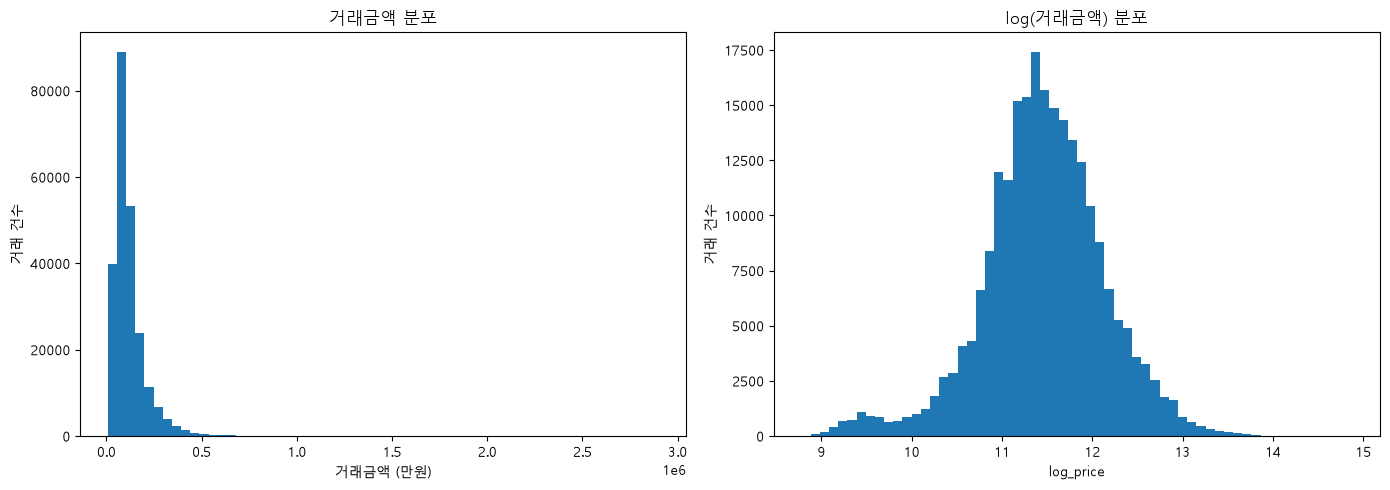

In [5]:
# ============================================================
# 거래금액 / log_price 분포
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

axes[0].hist(
    df["거래금액"],
    bins=60,
)

axes[0].set_title(
    "거래금액 분포"
)
axes[0].set_xlabel(
    "거래금액 (만원)"
)
axes[0].set_ylabel(
    "거래 건수"
)


axes[1].hist(
    df["log_price"],
    bins=60,
)

axes[1].set_title(
    "log(거래금액) 분포"
)
axes[1].set_xlabel(
    "log_price"
)
axes[1].set_ylabel(
    "거래 건수"
)

plt.tight_layout()
plt.show()

In [6]:
# ============================================================
# 거래가격 기술통계
# ============================================================

display(
    df[
        [
            "거래금액",
            "log_price",
            "평당가",
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
        ]
    )
    .T
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
거래금액,234302.0,117995.048642,90598.183195,6500.0,12000.0,30000.0,64500.0,94800.0,144000.0,281500.0,450000.0,2900000.0
log_price,234302.0,11.455031,0.68167,8.779711,9.392745,10.308986,11.074436,11.459535,11.877576,12.547891,13.017005,14.880222
평당가,234302.0,5100.459554,2760.607481,600.274968,1731.015763,2256.784369,3248.608921,4351.939331,6116.749458,10696.493705,15167.476885,34997.590608


In [7]:
# ============================================================
# 결측치 성격 분류
# ============================================================

drop_missing_cols = [
    "해제여부",
    "해제사유발생일",
]

structural_missing_cols = [
    "구_과거6개월_거래량",
    "서울_과거6개월_중위가격",
    "구_과거6개월_중위가격",
    "구_과거3개월_중위가격",
    "서울_과거3개월_중위가격",
    "구_과거3개월_거래량",
    "서울_과거3개월_거래량",
    "구_전월_가격변화율",
    "서울_전월_가격변화율",
    "서울_전월_거래량",
    "서울_전월_중위가격",
    "구_전월_중위평당가",
    "구_전월_중위가격",
    "구_전월_거래량",
    "전세가율_전월",
    "전세가율_과거3개월",
    "전세가율_과거6개월",
]

print("완전 결측 삭제 후보:", drop_missing_cols)
print("구조적 결측 Feature:", len(structural_missing_cols))

완전 결측 삭제 후보: ['해제여부', '해제사유발생일']
구조적 결측 Feature: 17


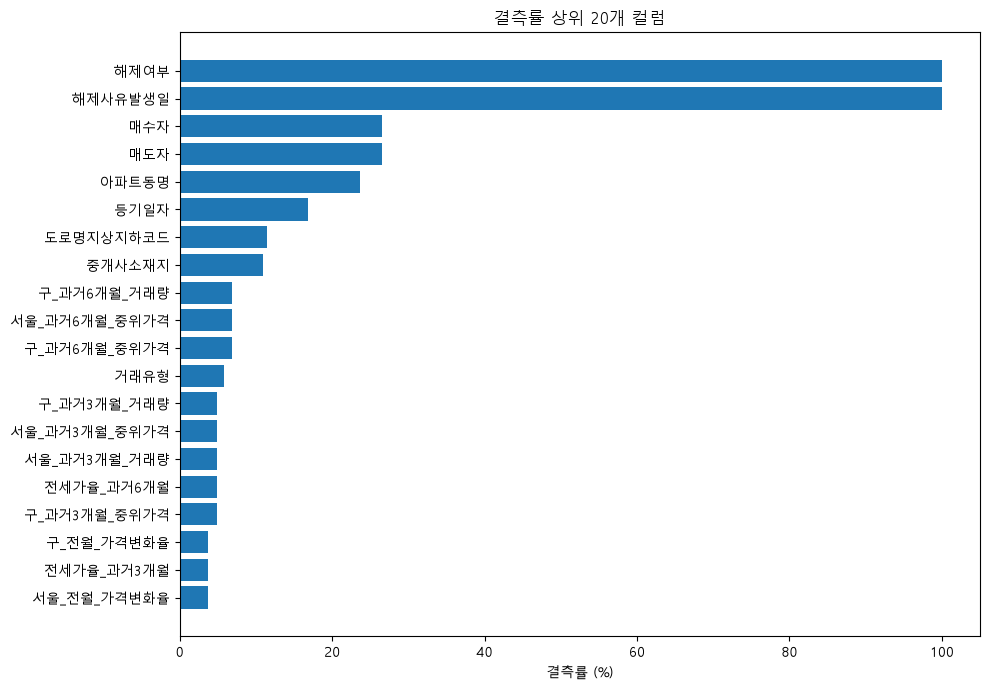

In [8]:
# ============================================================
# 결측률 상위 컬럼 시각화
# ============================================================

missing_rate = (
    df.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

missing_top20 = (
    missing_rate[
        missing_rate > 0
    ]
    .head(20)
    .sort_values()
)

plt.figure(figsize=(10, 7))

plt.barh(
    missing_top20.index,
    missing_top20.values,
)

plt.title("결측률 상위 20개 컬럼")
plt.xlabel("결측률 (%)")
plt.ylabel("")

plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# 월별 서울 아파트 시장 요약
# ============================================================

monthly_market = (
    df
    .groupby("거래월일자")
    .agg(
        거래금액_중위값=(
            "거래금액",
            "median",
        ),
        평당가_중위값=(
            "평당가",
            "median",
        ),
        거래량=(
            "transaction_id",
            "count",
        ),
    )
    .reset_index()
)

display(monthly_market.head())

,거래월일자,거래금액_중위값,평당가_중위값,거래량
0,2021-07-01,87000.0,4087.030323,4677
1,2021-08-01,91000.0,4261.136937,4060
2,2021-09-01,92000.0,4444.230230,2690
3,2021-10-01,89500.0,4308.318427,2196
4,2021-11-01,83100.0,4056.025891,1360


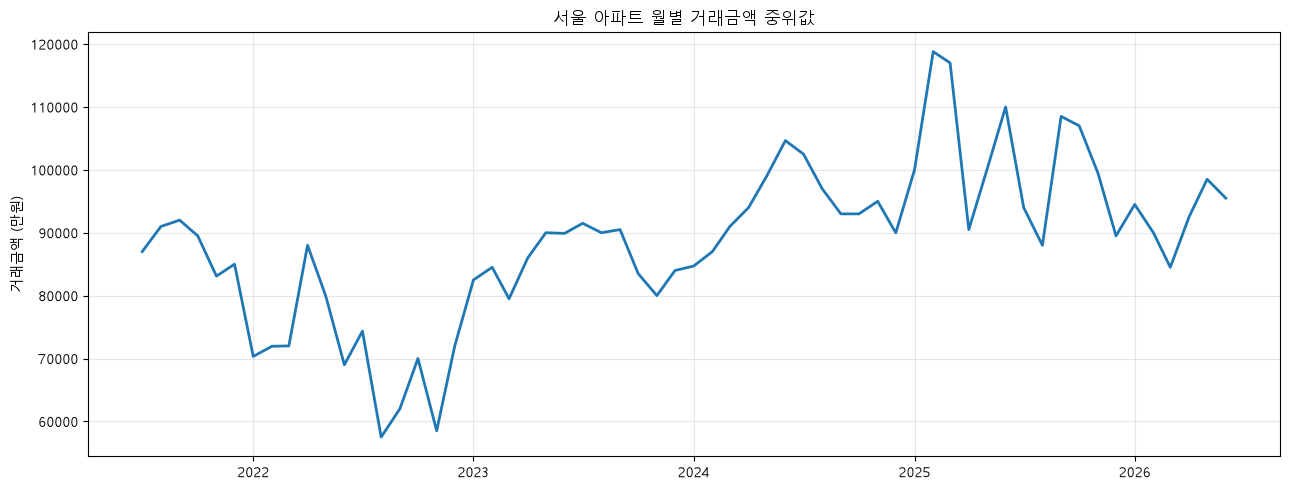

In [10]:
# ============================================================
# 월별 거래가격 추이
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 5)
)

ax.plot(
    monthly_market["거래월일자"],
    monthly_market["거래금액_중위값"],
    linewidth=2,
)

ax.set_title(
    "서울 아파트 월별 거래금액 중위값"
)
ax.set_ylabel(
    "거래금액 (만원)"
)
ax.set_xlabel("")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

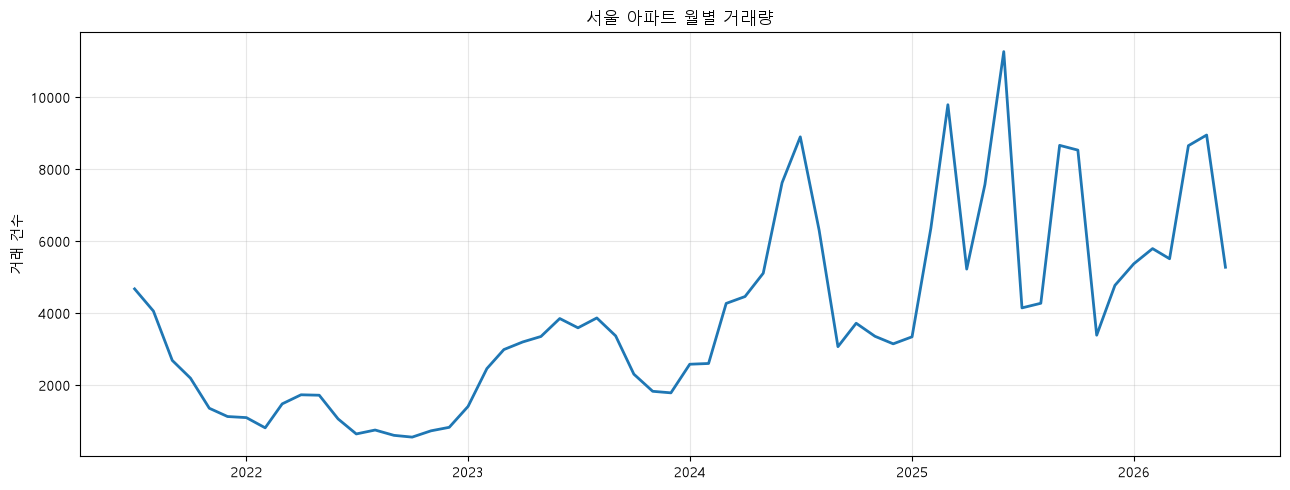

In [11]:
# ============================================================
# 월별 거래량 추이
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 5)
)

ax.plot(
    monthly_market["거래월일자"],
    monthly_market["거래량"],
    linewidth=2,
)

ax.set_title(
    "서울 아파트 월별 거래량"
)
ax.set_ylabel(
    "거래 건수"
)
ax.set_xlabel("")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

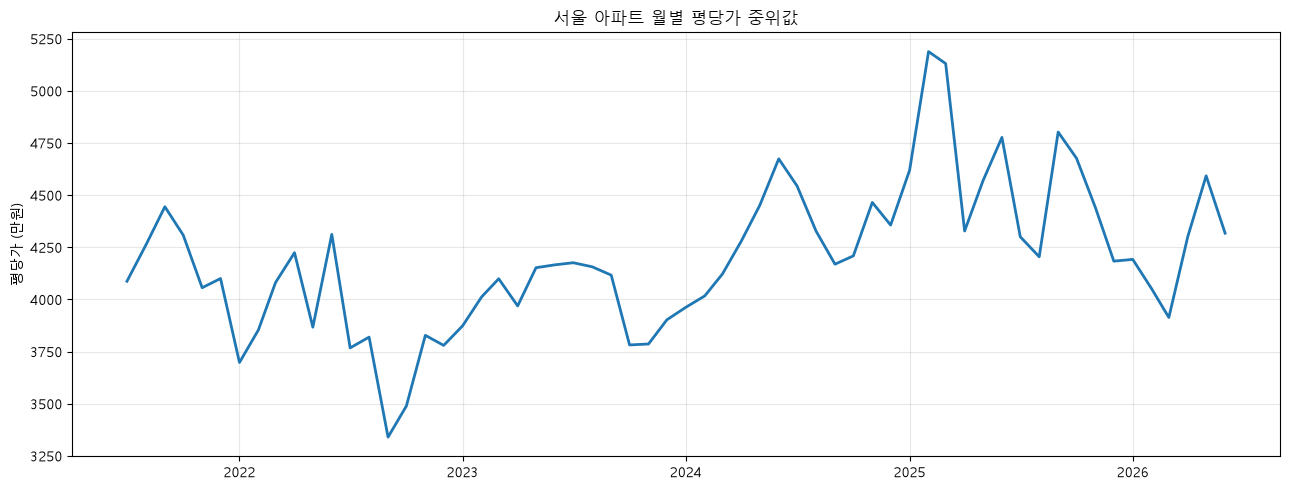

In [12]:
# ============================================================
# 월별 평당가 중위값
# ============================================================

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    monthly_market["거래월일자"],
    monthly_market["평당가_중위값"],
    linewidth=2,
)

ax.set_title("서울 아파트 월별 평당가 중위값")
ax.set_ylabel("평당가 (만원)")
ax.set_xlabel("")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

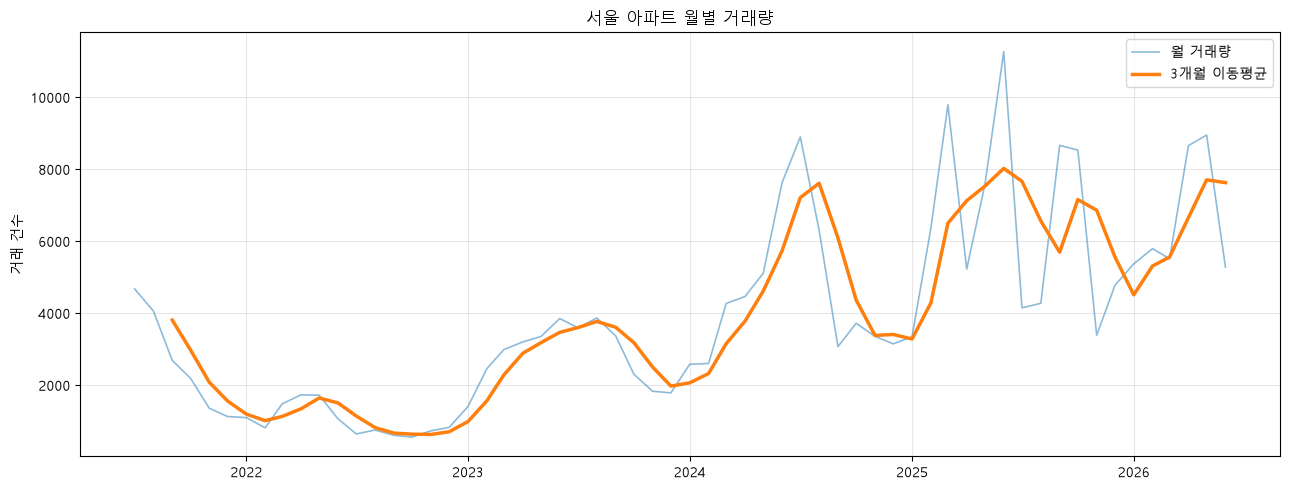

In [13]:
# ============================================================
# 거래량 3개월 이동평균
# ============================================================

monthly_market["거래량_3개월평균"] = (
    monthly_market["거래량"]
    .rolling(3)
    .mean()
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    monthly_market["거래월일자"],
    monthly_market["거래량"],
    linewidth=1.2,
    alpha=0.5,
    label="월 거래량",
)

ax.plot(
    monthly_market["거래월일자"],
    monthly_market["거래량_3개월평균"],
    linewidth=2.5,
    label="3개월 이동평균",
)

ax.set_title("서울 아파트 월별 거래량")
ax.set_ylabel("거래 건수")
ax.set_xlabel("")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

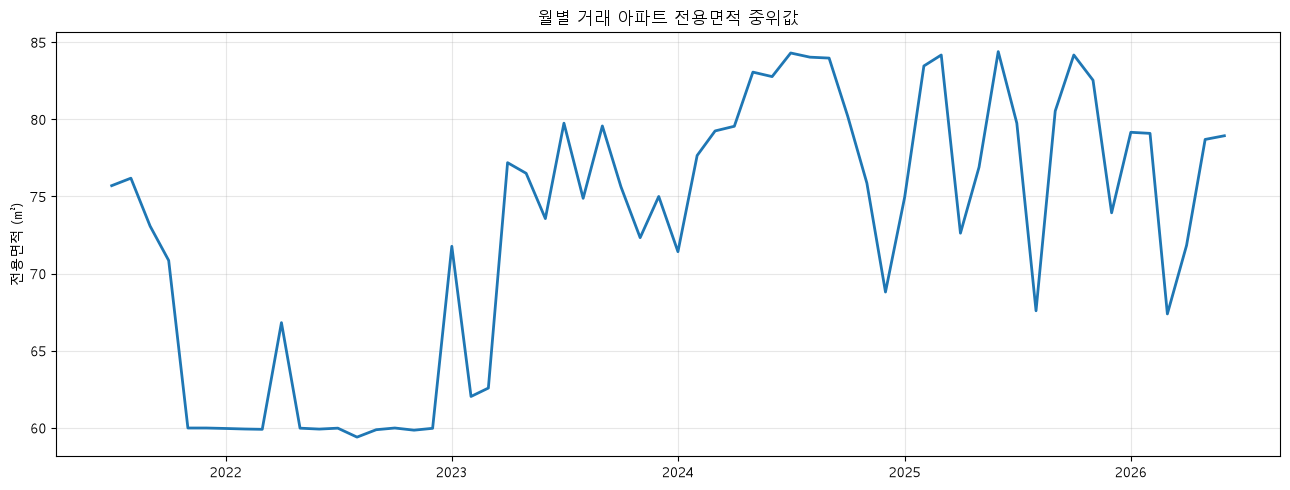

In [14]:
# ============================================================
# 월별 전용면적 중위값
# ============================================================

monthly_area = (
    df
    .groupby("거래월일자")
    ["전용면적"]
    .median()
    .reset_index(
        name="전용면적_중위값"
    )
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    monthly_area["거래월일자"],
    monthly_area["전용면적_중위값"],
    linewidth=2,
)

ax.set_title("월별 거래 아파트 전용면적 중위값")
ax.set_ylabel("전용면적 (㎡)")
ax.set_xlabel("")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# 월별 자치구 거래 비중 확인
# ============================================================

gu_monthly = (
    df
    .groupby(
        [
            "거래월일자",
            "시군구명",
        ]
    )
    .size()
    .reset_index(
        name="거래량"
    )
)

gu_monthly["월전체거래량"] = (
    gu_monthly
    .groupby("거래월일자")
    ["거래량"]
    .transform("sum")
)

gu_monthly["거래비중"] = (
    gu_monthly["거래량"]
    / gu_monthly["월전체거래량"]
)

display(
    gu_monthly
    .sort_values(
        [
            "거래월일자",
            "거래비중",
        ],
        ascending=[True, False],
    )
    .head(20)
)

,거래월일자,시군구명,거래량,월전체거래량,거래비중
8,2021-07-01,노원구,466,4677,0.099637
3,2021-07-01,강서구,372,4677,0.079538
6,2021-07-01,구로구,268,4677,0.057302
17,2021-07-01,송파구,253,4677,0.054095
16,2021-07-01,성북구,248,4677,0.053025
9,2021-07-01,도봉구,208,4677,0.044473
0,2021-07-01,강남구,205,4677,0.043832
24,2021-07-01,중랑구,203,4677,0.043404
14,2021-07-01,서초구,200,4677,0.042762
10,2021-07-01,동대문구,199,4677,0.042549


In [16]:
# ============================================================
# 전용면적 구간 생성
# ============================================================

df["전용면적구간"] = pd.cut(
    df["전용면적"],
    bins=[
        0,
        60,
        85,
        102,
        np.inf,
    ],
    labels=[
        "60㎡ 이하",
        "60~85㎡",
        "85~102㎡",
        "102㎡ 초과",
    ],
    right=False,
)

print(
    df["전용면적구간"]
    .value_counts()
    .sort_index()
)

전용면적구간
60㎡ 이하     101971
60~85㎡      96457
85~102㎡      5692
102㎡ 초과     30182
Name: count, dtype: int64


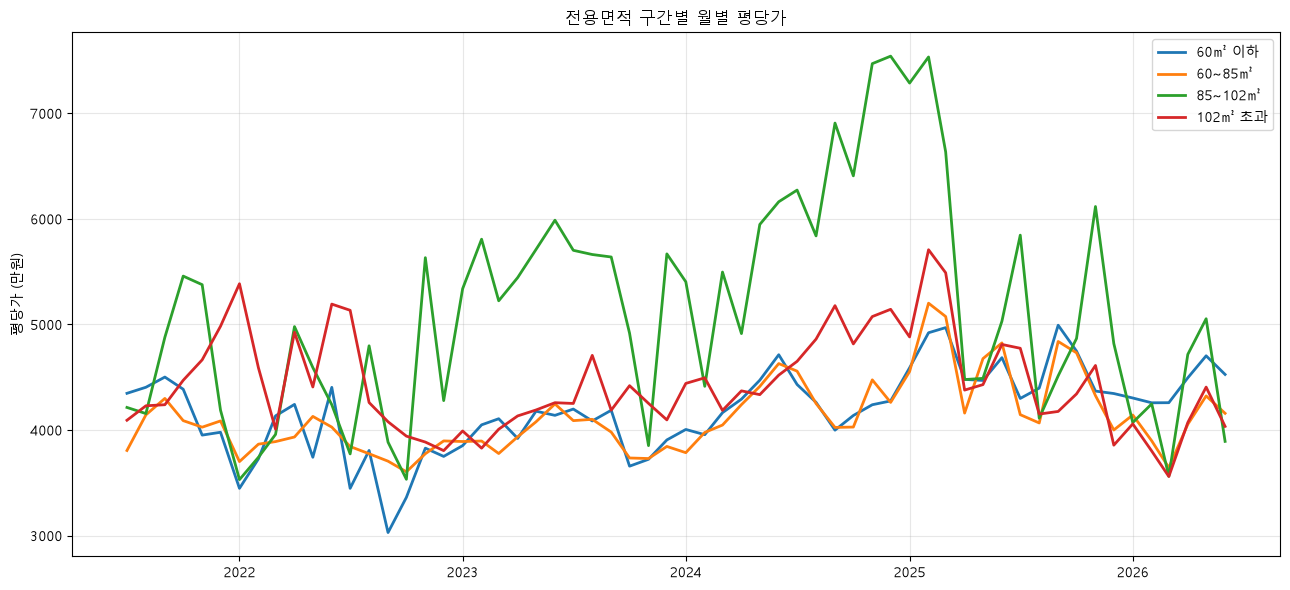

In [17]:
# ============================================================
# 면적구간별 월별 평당가
# ============================================================

area_price_monthly = (
    df
    .groupby(
        [
            "거래월일자",
            "전용면적구간",
        ],
        observed=True,
    )
    ["평당가"]
    .median()
    .reset_index()
)

fig, ax = plt.subplots(
    figsize=(13, 6)
)

for area_group in (
    area_price_monthly[
        "전용면적구간"
    ].unique()
):
    temp = area_price_monthly[
        area_price_monthly[
            "전용면적구간"
        ] == area_group
    ]

    ax.plot(
        temp["거래월일자"],
        temp["평당가"],
        linewidth=2,
        label=area_group,
    )

ax.set_title(
    "전용면적 구간별 월별 평당가"
)
ax.set_ylabel("평당가 (만원)")
ax.set_xlabel("")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# 자치구별 평당가 중위값
# ============================================================

gu_price = (
    df
    .groupby("시군구명")
    .agg(
        평당가_중위값=(
            "평당가",
            "median",
        ),
        거래량=(
            "transaction_id",
            "count",
        ),
    )
    .sort_values(
        "평당가_중위값"
    )
)

display(
    gu_price.sort_values(
        "평당가_중위값",
        ascending=False,
    )
)

,평당가_중위값,거래량
시군구명,,
강남구,9338.886405,12954
서초구,8139.139214,10086
용산구,7019.296102,4185
송파구,6743.132203,16150
성동구,6079.188730,10293
마포구,5723.337950,10205
광진구,5459.942193,5179
강동구,5033.684542,13627
동작구,5030.966767,9954


서울 아파트 거래금액은 거래된 주택의 면적 구성 변화에 영향을 받는 것으로 확인되었다. 특히 2024~2025년에는 전용면적 중위값이 증가하면서 거래금액 중위값도 상승하였다. 다만 같은 기간 평당가 역시 뚜렷하게 상승하여, 거래금액 상승을 면적 구성 변화만으로 설명할 수 없으며 실제 가격 수준의 회복 및 상승도 함께 나타난 것으로 판단된다.

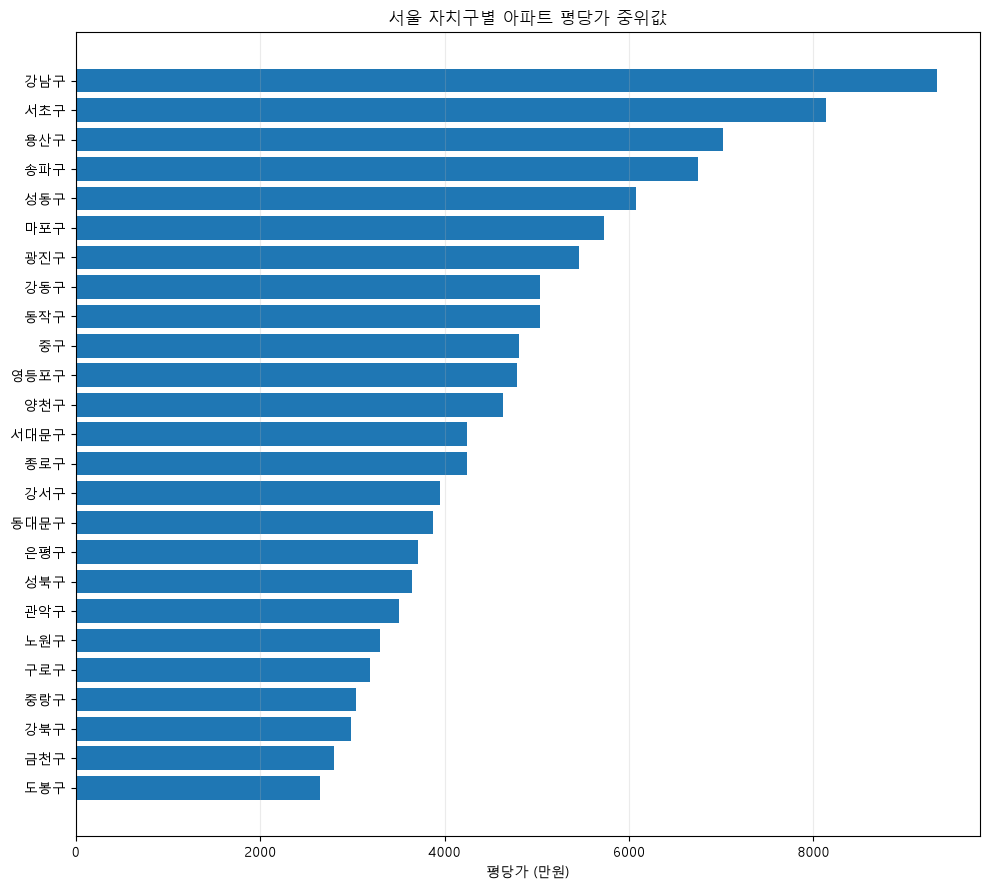

In [20]:
# ============================================================
# 자치구별 평당가 시각화
# ============================================================

gu_price_plot = (
    gu_price
    .sort_values(
        "평당가_중위값",
        ascending=True,
    )
)

fig, ax = plt.subplots(
    figsize=(10, 9)
)

ax.barh(
    gu_price_plot.index,
    gu_price_plot["평당가_중위값"],
)

ax.set_title(
    "서울 자치구별 아파트 평당가 중위값"
)

ax.set_xlabel(
    "평당가 (만원)"
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    alpha=0.25,
)

plt.tight_layout()
plt.show()

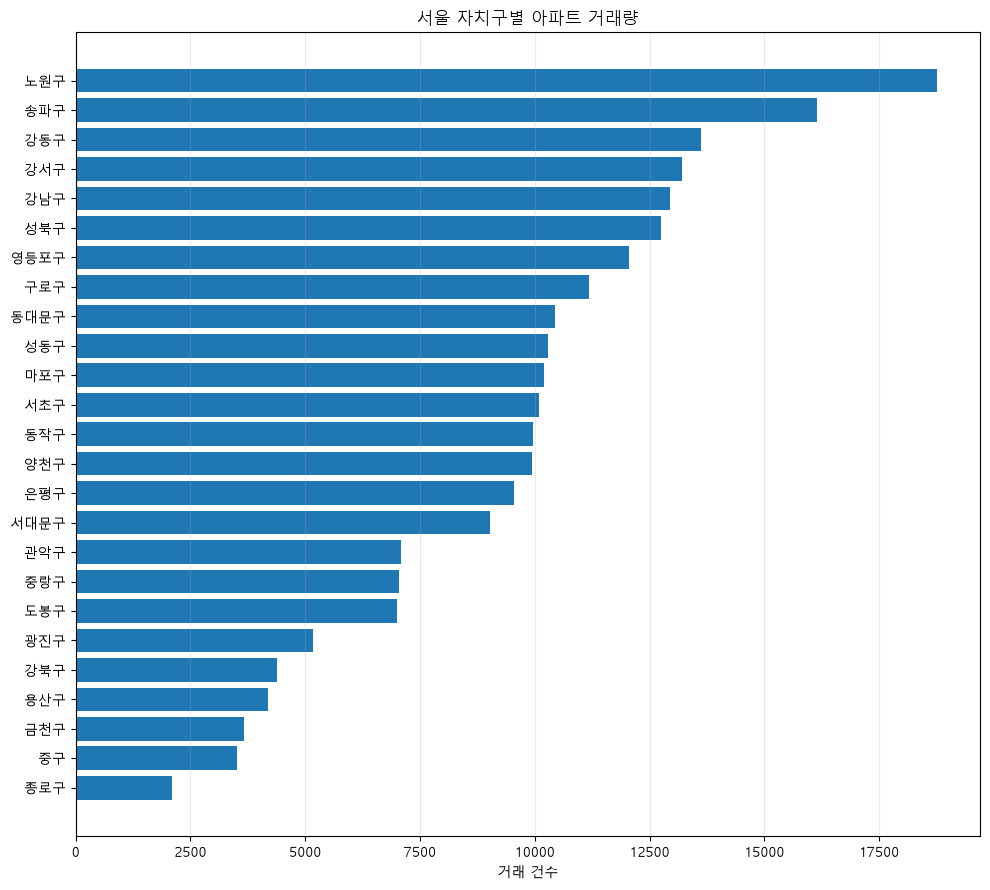

In [21]:
# ============================================================
# 자치구별 거래량
# ============================================================

gu_volume_plot = (
    gu_price
    .sort_values(
        "거래량",
        ascending=True,
    )
)

fig, ax = plt.subplots(
    figsize=(10, 9)
)

ax.barh(
    gu_volume_plot.index,
    gu_volume_plot["거래량"],
)

ax.set_title(
    "서울 자치구별 아파트 거래량"
)

ax.set_xlabel(
    "거래 건수"
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    alpha=0.25,
)

plt.tight_layout()
plt.show()

자치구별 평당가 중위값에서 뚜렷한 지역 격차가 확인되었다. 강남·서초·용산·송파 등 핵심 지역의 평당가가 높은 반면 도봉·금천·강북 등은 상대적으로 낮게 나타났다. 또한 거래량 순위는 가격 순위와 일치하지 않아, 서울 아파트 시장은 지역별 가격 수준과 거래 활성도가 서로 다른 구조를 보인다.

In [22]:
# ============================================================
# 입지 거리 Feature 확인
# ============================================================

location_distance_cols = [
    "역세권거리_m",
    "유치원거리_m",
    "초등학교거리_m",
    "중학교거리_m",
    "고등학교거리_m",
    "응급의료기관거리_km",
    "대규모점포거리_km",
    "주요일자리거리_km",
]

location_distance_cols = [
    col
    for col in location_distance_cols
    if col in df.columns
]

print("사용 가능한 입지 거리 피처:")
print(location_distance_cols)

display(
    df[location_distance_cols]
    .describe()
    .T
)

사용 가능한 입지 거리 피처:
['역세권거리_m', '유치원거리_m', '초등학교거리_m', '중학교거리_m', '고등학교거리_m', '응급의료기관거리_km', '대규모점포거리_km', '주요일자리거리_km']


,count,mean,std,min,25%,50%,75%,max
역세권거리_m,234302.0,531.752437,321.697386,24.436073,310.051661,461.863773,659.260223,3143.458506
유치원거리_m,234302.0,277.457905,165.344566,3.882308,157.776589,242.207325,368.293352,1330.590566
초등학교거리_m,234302.0,327.302267,155.782654,23.319600,207.831838,300.429989,420.021744,1768.785450
중학교거리_m,234302.0,465.116713,239.863885,24.066877,279.368480,428.630715,608.550402,2066.885015
고등학교거리_m,234302.0,607.920882,349.695174,27.363768,347.996717,537.361888,793.021992,2908.389959
응급의료기관거리_km,234302.0,1.239971,0.688347,0.029376,0.732115,1.164783,1.624423,4.626382
대규모점포거리_km,234302.0,0.621204,0.400910,0.000000,0.343741,0.548411,0.833438,3.492928
주요일자리거리_km,234302.0,5.317392,2.962110,0.016512,3.006061,4.790489,7.234001,13.716420


In [23]:
# ============================================================
# 입지 거리와 평당가 상관관계
# ============================================================

location_corr = (
    df[
        location_distance_cols
        + ["평당가"]
    ]
    .corr(numeric_only=True)["평당가"]
    .drop("평당가")
    .sort_values()
)

display(
    location_corr.to_frame(
        "평당가_상관계수"
    )
)

,평당가_상관계수
주요일자리거리_km,-0.392808
역세권거리_m,-0.169181
고등학교거리_m,-0.098012
대규모점포거리_km,-0.060408
응급의료기관거리_km,-0.040460
중학교거리_m,-0.040026
초등학교거리_m,-0.021170
유치원거리_m,0.045498


In [24]:
# ============================================================
# 거리 5분위별 평당가 요약 함수
# ============================================================

def make_distance_price_summary(
    data,
    distance_col,
    q=5,
):
    temp = data[
        [
            distance_col,
            "평당가",
        ]
    ].dropna().copy()

    temp["거리구간"] = pd.qcut(
        temp[distance_col],
        q=q,
        labels=False,
        duplicates="drop",
    )

    summary = (
        temp
        .groupby("거리구간")
        .agg(
            거리중위값=(
                distance_col,
                "median",
            ),
            평당가_중위값=(
                "평당가",
                "median",
            ),
            거래량=(
                "평당가",
                "size",
            ),
        )
        .reset_index()
    )

    return summary

,거리구간,거리중위값,평당가_중위값,거래량
0,0,209.591879,4702.024766,46953
1,1,346.253038,4631.934534,46775
2,2,461.939218,4741.652525,47099
3,3,614.945929,4201.793574,46616
4,4,928.849431,3695.587197,46859


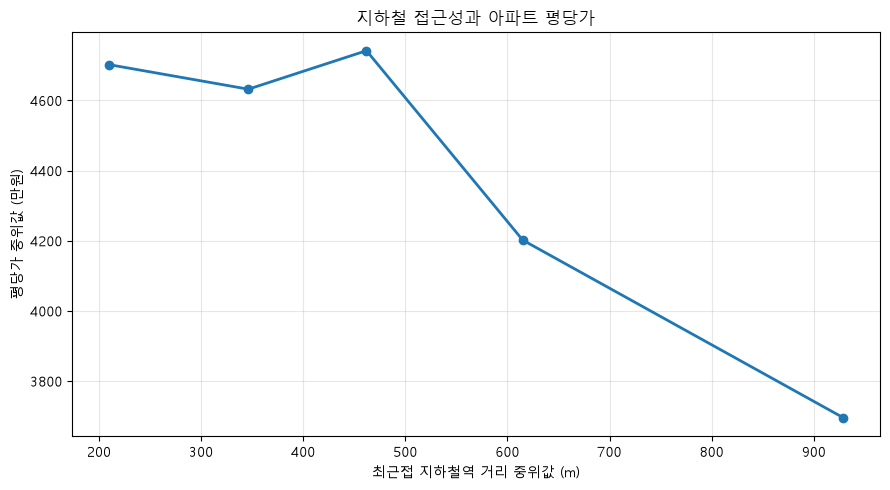

In [25]:
# ============================================================
# 지하철 거리 구간별 평당가
# ============================================================

subway_price = (
    make_distance_price_summary(
        df,
        "역세권거리_m",
    )
)

display(subway_price)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    subway_price["거리중위값"],
    subway_price["평당가_중위값"],
    marker="o",
    linewidth=2,
)

ax.set_title(
    "지하철 접근성과 아파트 평당가"
)
ax.set_xlabel(
    "최근접 지하철역 거리 중위값 (m)"
)
ax.set_ylabel(
    "평당가 중위값 (만원)"
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

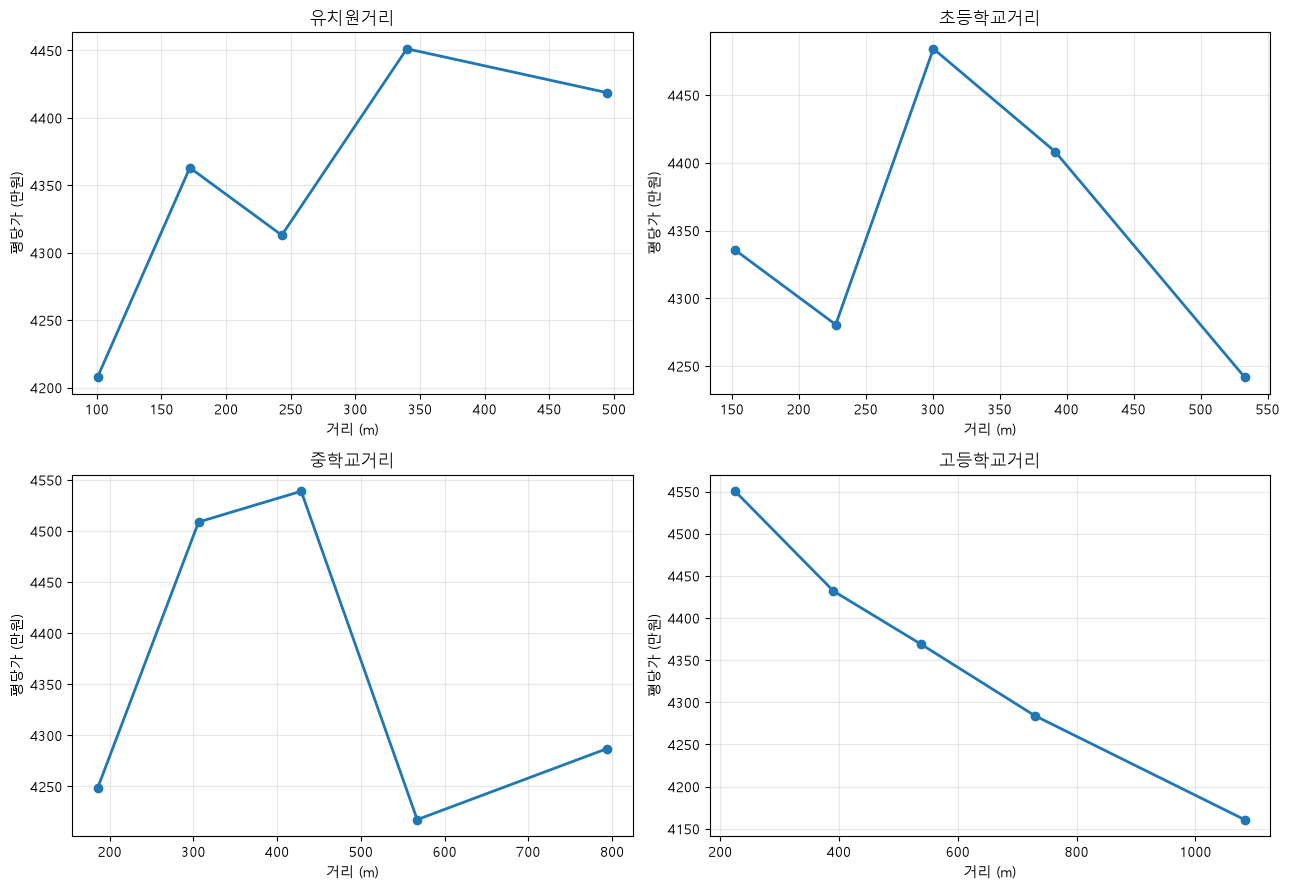

In [26]:
# ============================================================
# 교육시설 거리와 평당가
# ============================================================

school_distance_cols = [
    col
    for col in [
        "유치원거리_m",
        "초등학교거리_m",
        "중학교거리_m",
        "고등학교거리_m",
    ]
    if col in df.columns
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9),
)

axes = axes.flatten()

for ax, col in zip(
    axes,
    school_distance_cols,
):
    summary = (
        make_distance_price_summary(
            df,
            col,
        )
    )

    ax.plot(
        summary["거리중위값"],
        summary["평당가_중위값"],
        marker="o",
        linewidth=2,
    )

    ax.set_title(col.replace("_m", ""))
    ax.set_xlabel("거리 (m)")
    ax.set_ylabel("평당가 (만원)")
    ax.grid(alpha=0.3)

for ax in axes[
    len(school_distance_cols):
]:
    ax.axis("off")

plt.tight_layout()
plt.show()

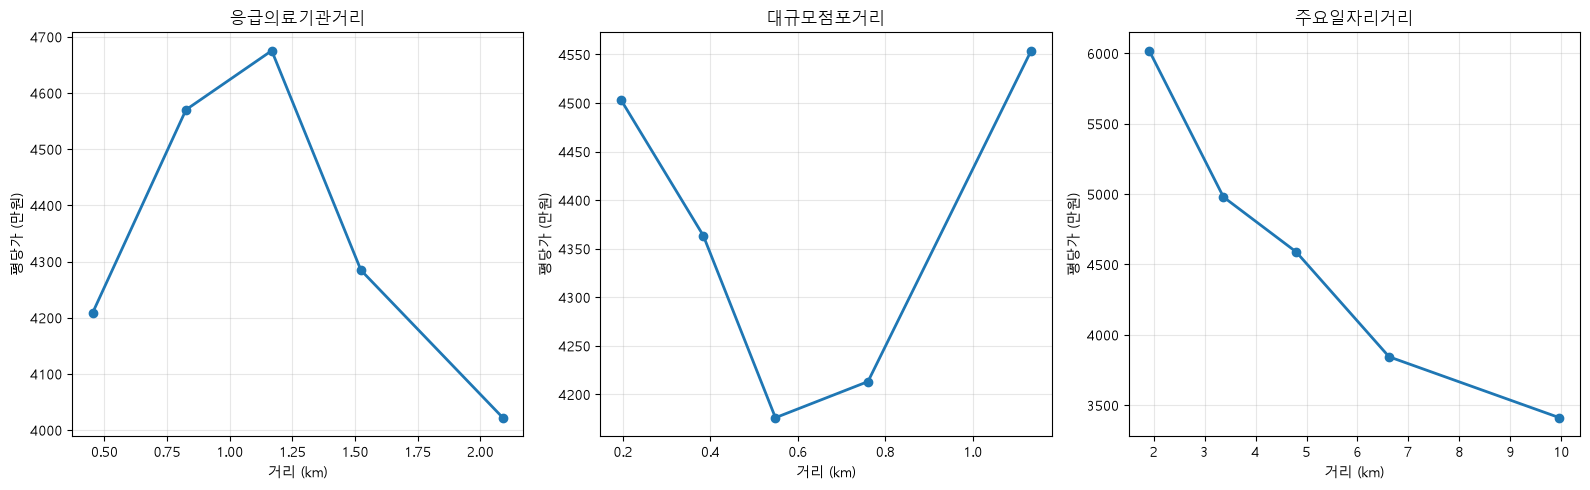

In [27]:
# ============================================================
# 생활입지 거리와 평당가
# ============================================================

living_distance_cols = [
    "응급의료기관거리_km",
    "대규모점포거리_km",
    "주요일자리거리_km",
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

for ax, col in zip(
    axes,
    living_distance_cols,
):
    summary = (
        make_distance_price_summary(
            df,
            col,
        )
    )

    ax.plot(
        summary["거리중위값"],
        summary["평당가_중위값"],
        marker="o",
        linewidth=2,
    )

    ax.set_title(
        col.replace("_km", "")
    )
    ax.set_xlabel("거리 (km)")
    ax.set_ylabel("평당가 (만원)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# ============================================================
# 자치구·월 가격 수준 보정
# ============================================================

df["구월_평당가_중위값"] = (
    df
    .groupby(
        [
            "거래월일자",
            "시군구명",
        ]
    )["평당가"]
    .transform("median")
)

df["상대평당가"] = (
    df["평당가"]
    / df["구월_평당가_중위값"]
)

display(
    df[
        [
            "평당가",
            "구월_평당가_중위값",
            "상대평당가",
        ]
    ]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
평당가,234302.0,5100.459554,2760.607481,600.274968,3248.608921,4351.939331,6116.749458,34997.590608
구월_평당가_중위값,234302.0,4907.162484,1868.625612,1377.416667,3504.340349,4381.236598,5863.701473,12860.398897
상대평당가,234302.0,1.039180,0.345221,0.118083,0.808485,1.000000,1.223179,6.891106


In [29]:
# ============================================================
# 지역·시간 보정 후 입지 상관관계
# ============================================================

location_relative_corr = (
    df[
        location_distance_cols
        + ["상대평당가"]
    ]
    .corr(numeric_only=True)["상대평당가"]
    .drop("상대평당가")
    .sort_values()
)

corr_compare = pd.DataFrame({
    "단순_평당가상관": location_corr,
    "구월_보정후상관": location_relative_corr,
})

display(
    corr_compare
    .sort_values(
        "구월_보정후상관"
    )
)

,단순_평당가상관,구월_보정후상관
역세권거리_m,-0.169181,-0.143859
유치원거리_m,0.045498,-0.114622
고등학교거리_m,-0.098012,-0.099760
초등학교거리_m,-0.021170,-0.098025
주요일자리거리_km,-0.392808,-0.078887
응급의료기관거리_km,-0.040460,-0.067358
대규모점포거리_km,-0.060408,-0.062341
중학교거리_m,-0.040026,-0.052410


In [36]:
# ============================================================
# 입지 상관관계: 평당가 vs log 평당가
# ============================================================

price_corr = (
    df[
        location_distance_cols
        + [
            "평당가",
            "log_평당가",
        ]
    ]
    .corr(numeric_only=True)
)

corr_compare_price = pd.DataFrame({
    "평당가_상관": (
        price_corr["평당가"]
        .drop(
            [
                "평당가",
                "log_평당가",
            ]
        )
    ),
    "log평당가_상관": (
        price_corr["log_평당가"]
        .drop(
            [
                "평당가",
                "log_평당가",
            ]
        )
    ),
})

display(
    corr_compare_price
    .sort_values("log평당가_상관")
)

,평당가_상관,log평당가_상관
주요일자리거리_km,-0.392808,-0.404118
역세권거리_m,-0.169181,-0.199737
고등학교거리_m,-0.098012,-0.099556
응급의료기관거리_km,-0.040460,-0.055201
대규모점포거리_km,-0.060408,-0.044376
중학교거리_m,-0.040026,-0.033779
초등학교거리_m,-0.021170,-0.025117
유치원거리_m,0.045498,0.034844


In [30]:
# ============================================================
# 거리 5분위별 상대평당가
# ============================================================

def make_relative_price_summary(
    data,
    distance_col,
    q=5,
):
    temp = data[
        [
            distance_col,
            "상대평당가",
        ]
    ].dropna().copy()

    temp["거리구간"] = pd.qcut(
        temp[distance_col],
        q=q,
        labels=False,
        duplicates="drop",
    )

    return (
        temp
        .groupby("거리구간")
        .agg(
            거리중위값=(
                distance_col,
                "median",
            ),
            상대평당가_중위값=(
                "상대평당가",
                "median",
            ),
            거래량=(
                "상대평당가",
                "size",
            ),
        )
        .reset_index()
    )

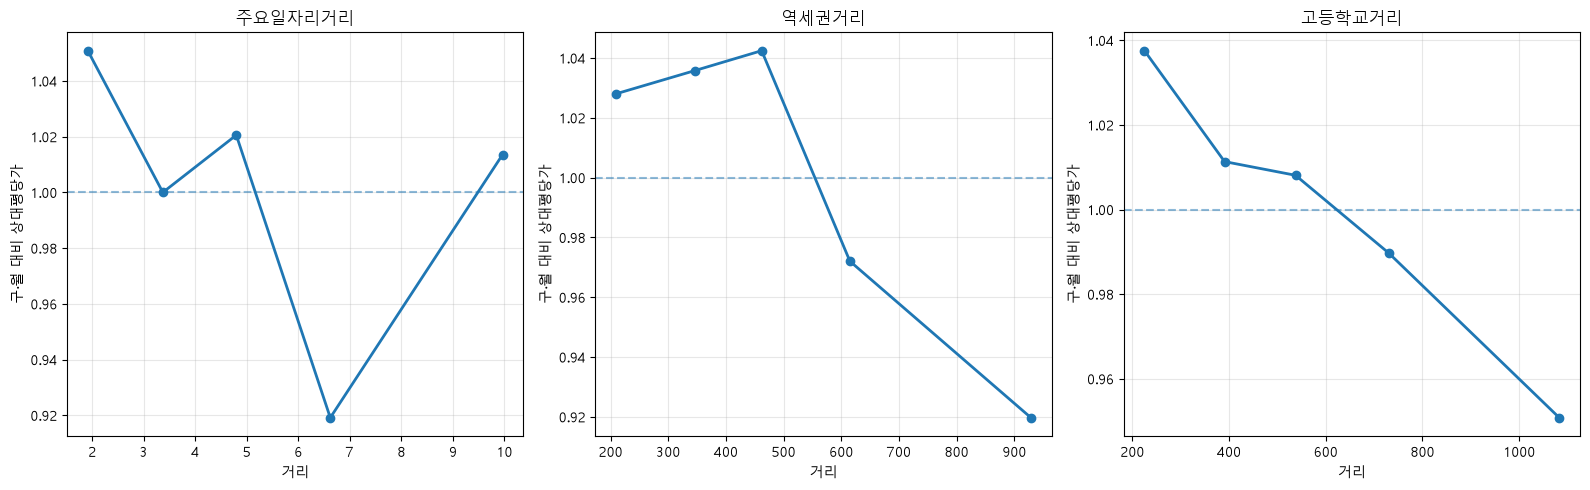

In [31]:
# ============================================================
# 핵심 입지 Feature 지역효과 보정
# ============================================================

key_location_cols = [
    "주요일자리거리_km",
    "역세권거리_m",
    "고등학교거리_m",
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

for ax, col in zip(
    axes,
    key_location_cols,
):
    summary = make_relative_price_summary(
        df,
        col,
    )

    ax.plot(
        summary["거리중위값"],
        summary["상대평당가_중위값"],
        marker="o",
        linewidth=2,
    )

    ax.axhline(
        1,
        linestyle="--",
        alpha=0.5,
    )

    ax.set_title(
        col
        .replace("_km", "")
        .replace("_m", "")
    )

    ax.set_xlabel("거리")
    ax.set_ylabel("구·월 대비 상대평당가")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
# ============================================================
# 월별 전월세 시장 요약
# ============================================================

monthly_rent = (
    df
    .groupby("거래월일자")
    .agg(
        매매평당가=("평당가", "median"),
        전세평당가_전월=(
            "전세평당가_전월",
            "median",
        ),
        전세가율_전월=(
            "전세가율_전월",
            "median",
        ),
        월세비중_전월=(
            "월세비중_전월",
            "median",
        ),
    )
    .reset_index()
)

display(monthly_rent.head())

,거래월일자,매매평당가,전세평당가_전월,전세가율_전월,월세비중_전월
0,2021-07-01,4087.030323,2095.177043,<NA>,0.343750
1,2021-08-01,4261.136937,2167.568173,0.506911,0.364188
2,2021-09-01,4444.230230,2175.96962,0.492643,0.355932
3,2021-10-01,4308.318427,2214.398223,0.478274,0.388235
4,2021-11-01,4056.025891,2295.154154,0.484533,0.366197


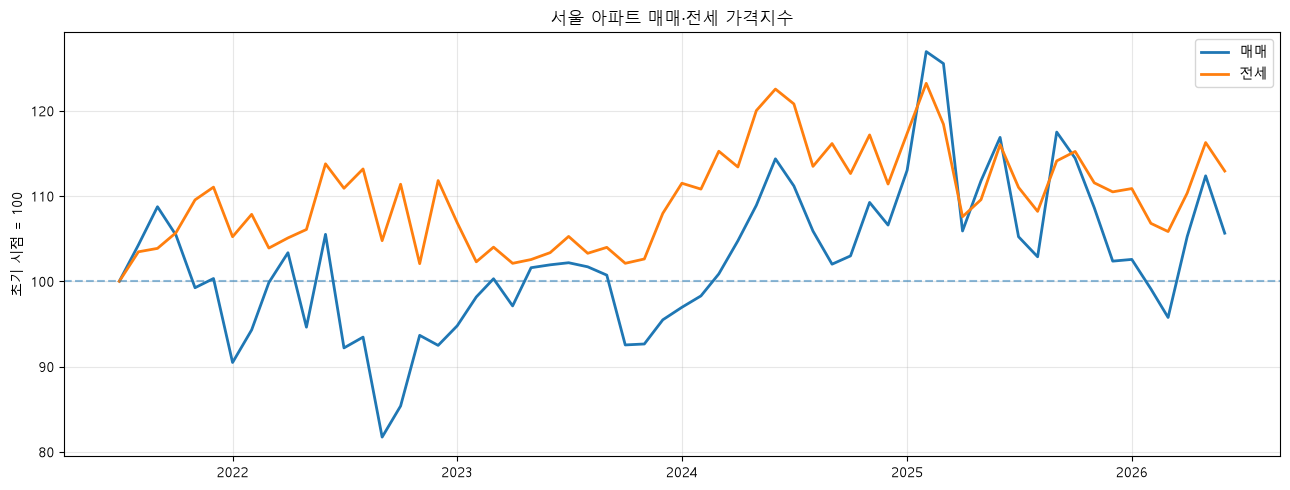

In [33]:
# ============================================================
# 매매 / 전세 가격지수 비교
# ============================================================

price_index = monthly_rent[
    [
        "거래월일자",
        "매매평당가",
        "전세평당가_전월",
    ]
].copy()

for col in [
    "매매평당가",
    "전세평당가_전월",
]:
    first_valid = (
        price_index[col]
        .dropna()
        .iloc[0]
    )

    price_index[f"{col}_지수"] = (
        price_index[col]
        / first_valid
        * 100
    )

fig, ax = plt.subplots(
    figsize=(13, 5)
)

ax.plot(
    price_index["거래월일자"],
    price_index["매매평당가_지수"],
    linewidth=2,
    label="매매",
)

ax.plot(
    price_index["거래월일자"],
    price_index["전세평당가_전월_지수"],
    linewidth=2,
    label="전세",
)

ax.axhline(
    100,
    linestyle="--",
    alpha=0.5,
)

ax.set_title("서울 아파트 매매·전세 가격지수")
ax.set_ylabel("초기 시점 = 100")
ax.set_xlabel("")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

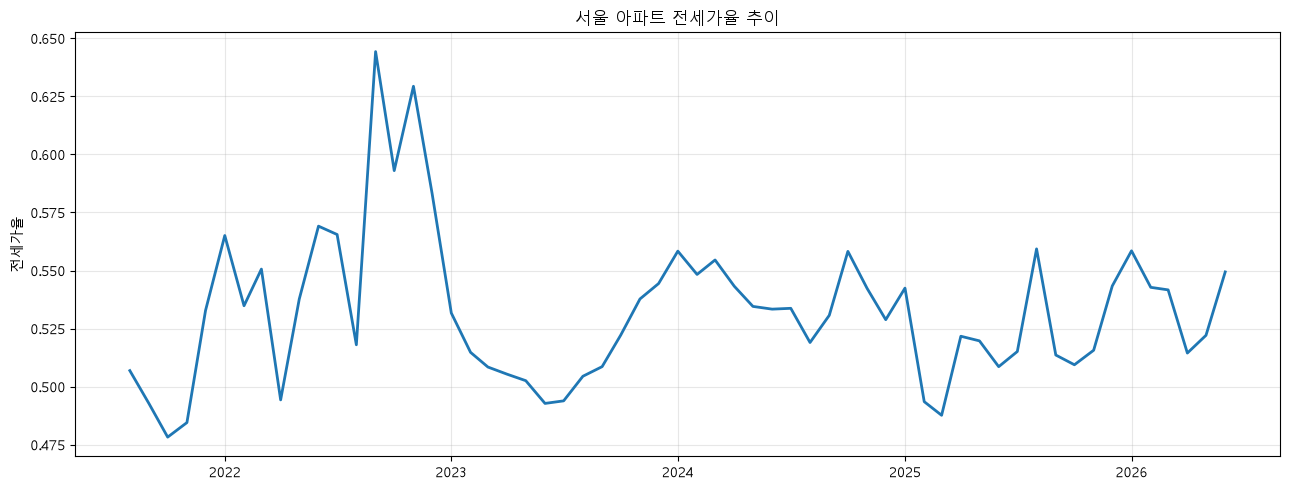

In [34]:
# ============================================================
# 월별 전세가율 추이
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 5)
)

ax.plot(
    monthly_rent["거래월일자"],
    monthly_rent["전세가율_전월"],
    linewidth=2,
)

ax.set_title("서울 아파트 전세가율 추이")
ax.set_ylabel("전세가율")
ax.set_xlabel("")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

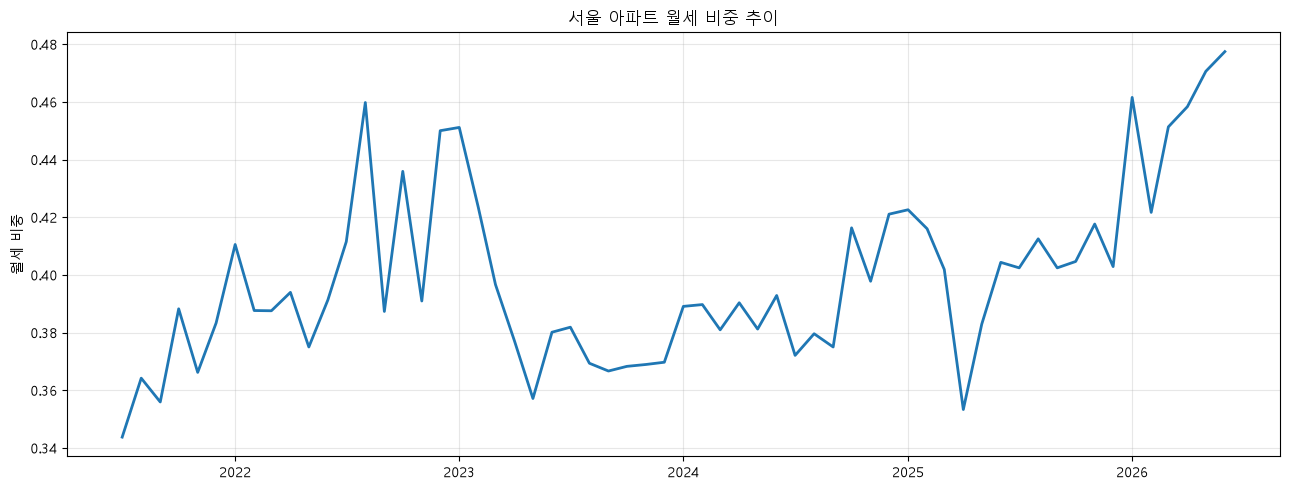

In [35]:
# ============================================================
# 월별 월세 비중 추이
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 5)
)

ax.plot(
    monthly_rent["거래월일자"],
    monthly_rent["월세비중_전월"],
    linewidth=2,
)

ax.set_title("서울 아파트 월세 비중 추이")
ax.set_ylabel("월세 비중")
ax.set_xlabel("")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

2021~2022
매매가격 변동성이 크고 하락구간 존재
전세가격은 매매보다 상대적으로 안정적

2022년 하반기
전세가율이 0.60~0.65 수준까지 상승
→ 매매가격 대비 전세가격이 상대적으로 강했던 구간

2023~2024
매매·전세 모두 회복
전세가율은 대체로 0.50~0.56 수준

2025
매매가격이 강하게 상승한 시점에서
전세가율이 약 0.49까지 낮아짐
→ 매매가가 전세가보다 상대적으로 빠르게 상승한 구간

2025~2026
월세비중 상승
→ 2026년에는 약 0.47~0.48 수준

In [37]:
# ============================================================
# 월별 매매가격 / 금리 요약
# ============================================================

monthly_macro = (
    df
    .groupby("거래월일자")
    .agg(
        매매평당가=(
            "평당가",
            "median",
        ),
        기준금리=(
            "기준금리_전월",
            "first",
        ),
        주담대금리=(
            "주담대금리_전월",
            "first",
        ),
        전세대출금리=(
            "전세대출금리_전월",
            "first",
        ),
    )
    .reset_index()
)

display(monthly_macro.head())

,거래월일자,매매평당가,기준금리,주담대금리,전세대출금리
0,2021-07-01,4087.030323,0.50,2.74,2.52
1,2021-08-01,4261.136937,0.50,2.81,2.64
2,2021-09-01,4444.230230,0.75,2.88,2.72
3,2021-10-01,4308.318427,0.75,3.01,2.86
4,2021-11-01,4056.025891,0.75,3.26,3.13


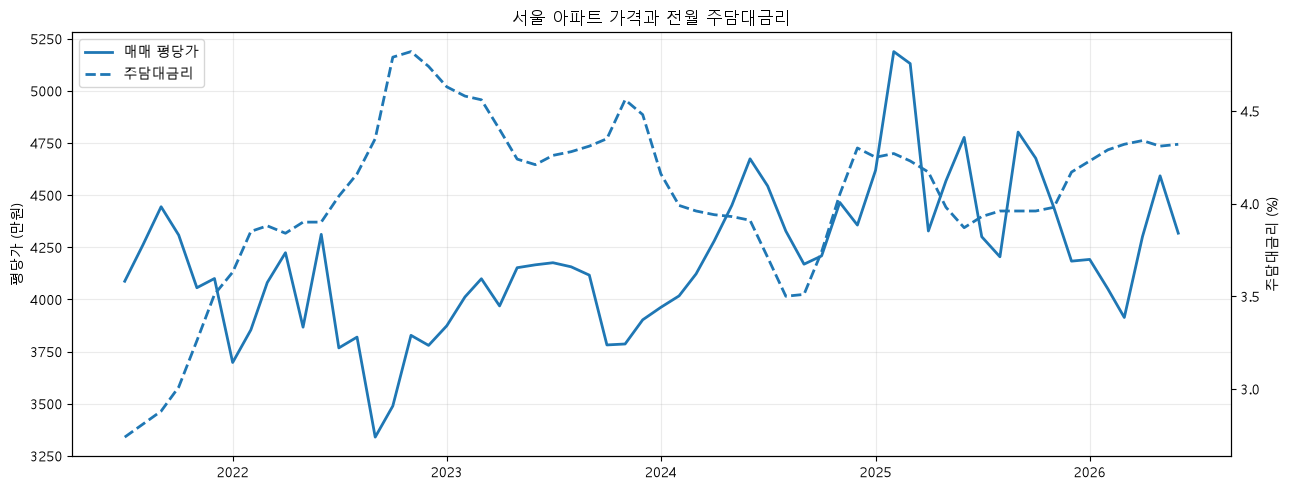

In [38]:
# ============================================================
# 매매 평당가와 주담대금리
# ============================================================

fig, ax1 = plt.subplots(
    figsize=(13, 5)
)

ax1.plot(
    monthly_macro["거래월일자"],
    monthly_macro["매매평당가"],
    linewidth=2,
    label="매매 평당가",
)

ax1.set_ylabel(
    "평당가 (만원)"
)
ax1.set_xlabel("")

ax2 = ax1.twinx()

ax2.plot(
    monthly_macro["거래월일자"],
    monthly_macro["주담대금리"],
    linewidth=2,
    linestyle="--",
    label="주담대금리",
)

ax2.set_ylabel(
    "주담대금리 (%)"
)

ax1.set_title(
    "서울 아파트 가격과 전월 주담대금리"
)

ax1.grid(alpha=0.25)

lines1, labels1 = (
    ax1.get_legend_handles_labels()
)

lines2, labels2 = (
    ax2.get_legend_handles_labels()
)

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left",
)

plt.tight_layout()
plt.show()

2021~2022
금리 ↑
가격 ↓ ?

2023
높은 금리 유지 중
가격 회복 시작 ?

2024~2026
금리 변화와 가격 흐름이
항상 동시에 움직이는가?

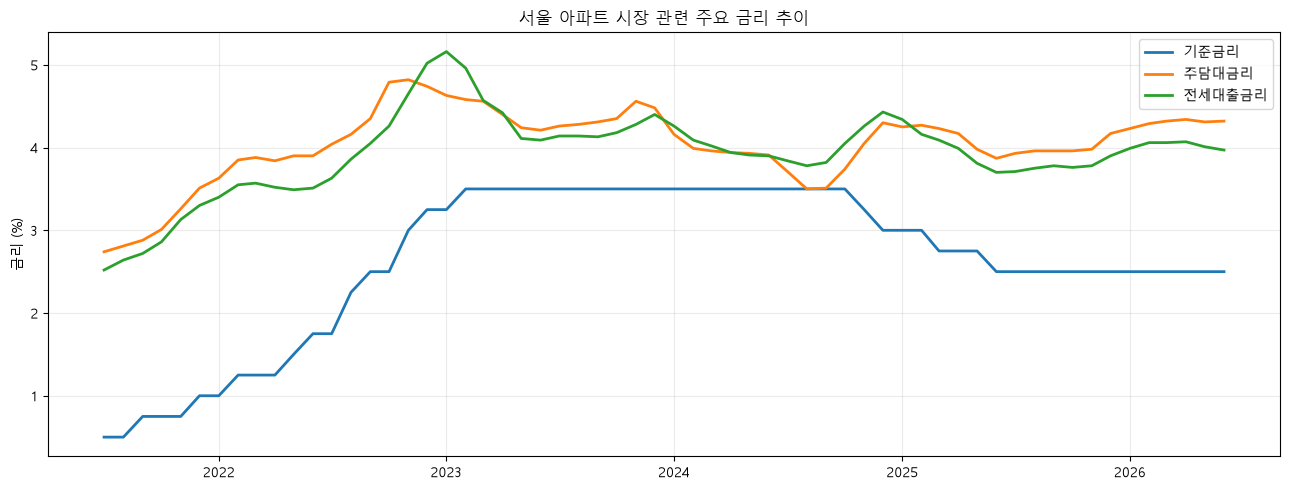

In [39]:
# ============================================================
# 주요 금리 추이
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 5)
)

for col in [
    "기준금리",
    "주담대금리",
    "전세대출금리",
]:
    ax.plot(
        monthly_macro["거래월일자"],
        monthly_macro[col],
        linewidth=2,
        label=col,
    )

ax.set_title(
    "서울 아파트 시장 관련 주요 금리 추이"
)

ax.set_ylabel("금리 (%)")
ax.set_xlabel("")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

DSR 단계 변경  
스트레스 DSR 단계 변경  
규제지역 변경  
주담대 규제 강화  
         ↓  
그 시점을 가격·거래량 그래프 위에 표시  

In [42]:
# ============================================================
# 정책 이벤트 로드
# ============================================================

POLICY_PATH = (
    EXTERNAL_DIR
    / "housing_policy_events_v1.csv"
)

policy_events = pd.read_csv(
    POLICY_PATH
)

policy_events["model_effective_month"] = (
    pd.to_datetime(
        policy_events["model_effective_month"]
    )
)

policy_events = (
    policy_events[
        policy_events["v1_use"] == 1
    ]
    .sort_values("model_effective_month")
    .reset_index(drop=True)
)

display(
    policy_events[
        [
            "model_effective_month",
            "policy_category",
            "policy_name",
            "direction",
        ]
    ]
)

,model_effective_month,policy_category,policy_name,direction
0,2021-07-01,DSR,차주단위 DSR 1단계,강화
1,2022-01-01,DSR,차주단위 DSR 2단계,강화
2,2022-07-01,DSR,차주단위 DSR 3단계,강화
3,2023-02-01,규제지역,서울 규제지역 대폭 해제,완화
4,2024-03-01,스트레스DSR,스트레스 DSR 1단계,강화
5,2024-09-01,스트레스DSR,스트레스 DSR 2단계,강화
6,2025-07-01,주담대규제,수도권 가계부채 관리 강화,강화
7,2025-07-01,스트레스DSR,스트레스 DSR 3단계,강화
8,2025-11-01,규제지역,서울 전역 규제지역 확대 지정,강화
9,2025-11-01,주담대규제,주택가격별 주담대 한도 차등화,강화


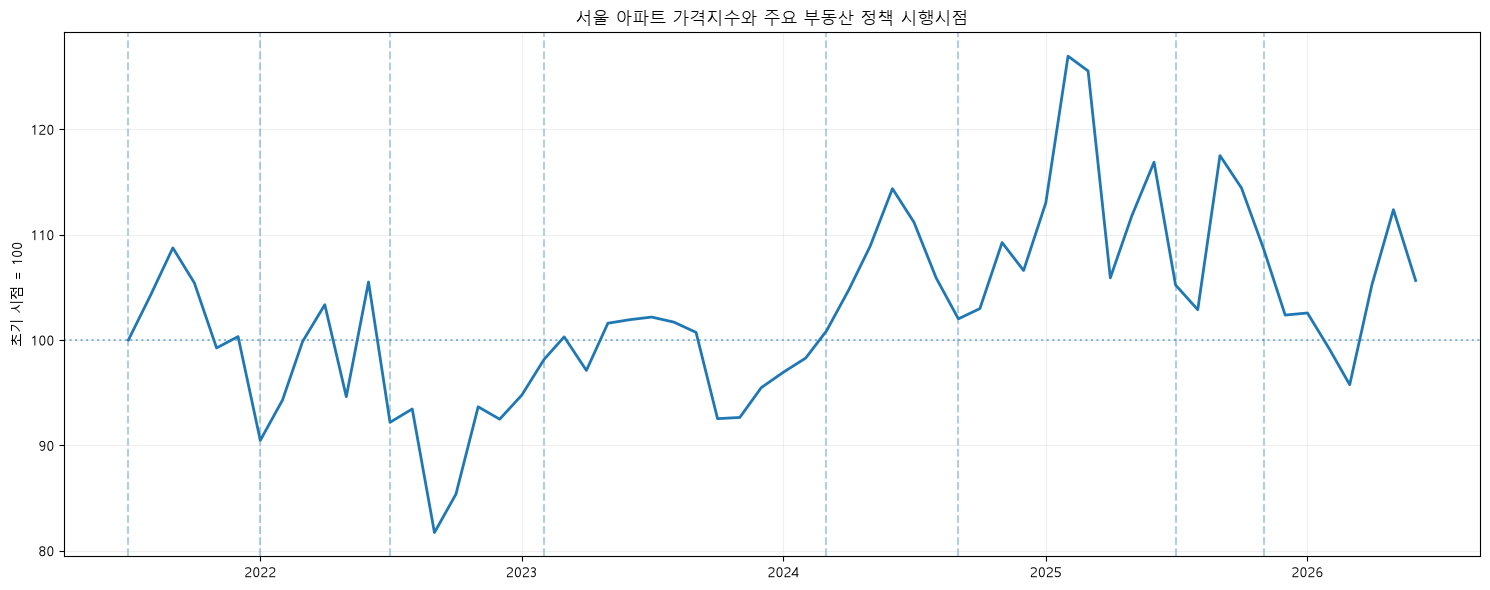

In [44]:
# ============================================================
# 매매 가격지수 + 정책 이벤트
# ============================================================

policy_market = (
    df
    .groupby("거래월일자")
    .agg(
        평당가=("평당가", "median"),
        거래량=("transaction_id", "count"),
    )
    .reset_index()
)

policy_market["평당가지수"] = (
    policy_market["평당가"]
    / policy_market["평당가"].iloc[0]
    * 100
)

fig, ax = plt.subplots(
    figsize=(15, 6)
)

ax.plot(
    policy_market["거래월일자"],
    policy_market["평당가지수"],
    linewidth=2,
    label="매매 평당가지수",
)

for policy_date in (
    policy_events["model_effective_month"]
    .drop_duplicates()
):
    ax.axvline(
        policy_date,
        linestyle="--",
        alpha=0.35,
    )

ax.axhline(
    100,
    linestyle=":",
    alpha=0.5,
)

ax.set_title(
    "서울 아파트 가격지수와 주요 부동산 정책 시행시점"
)
ax.set_ylabel("초기 시점 = 100")
ax.set_xlabel("")

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

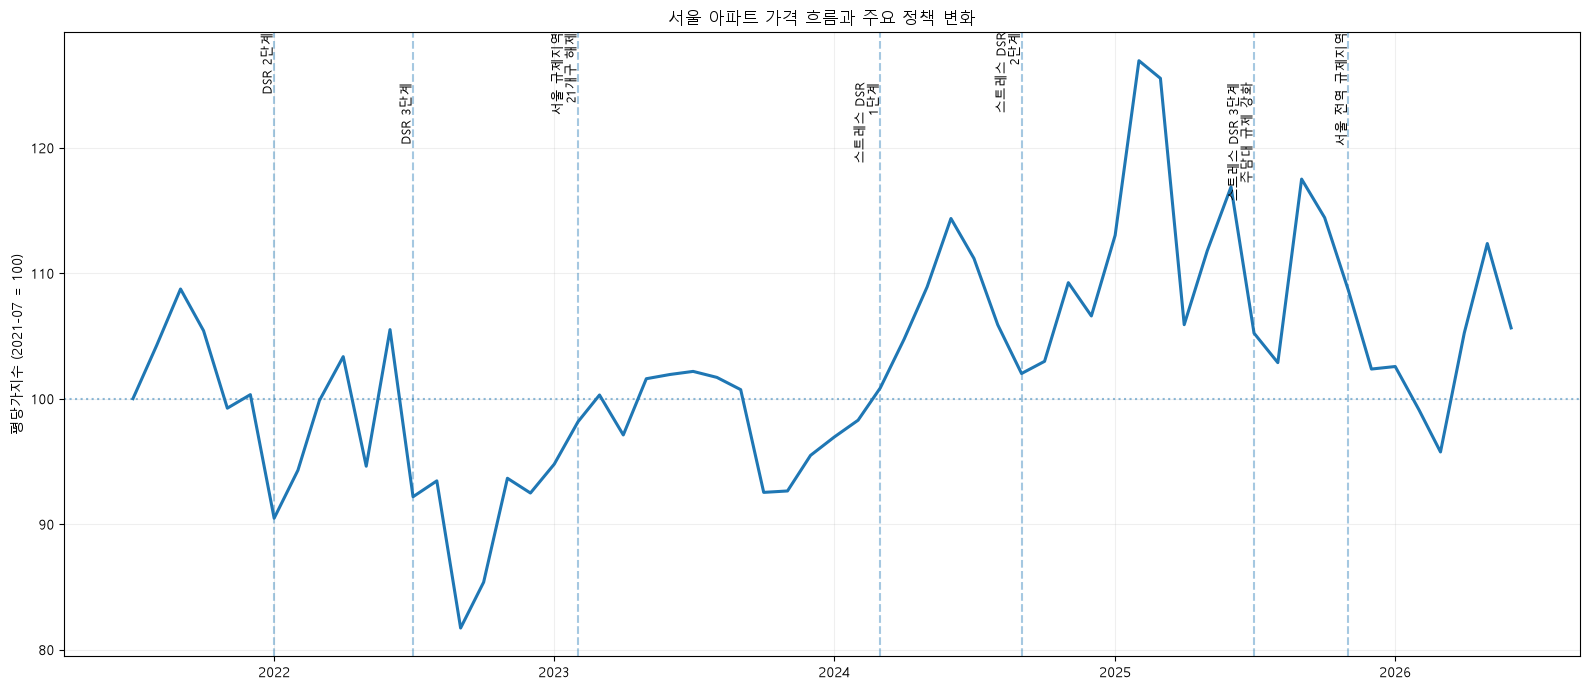

In [45]:
# ============================================================
# 핵심 정책 이벤트 표시
# ============================================================

key_policy_events = {
    pd.Timestamp("2022-01-01"):
        "DSR 2단계",

    pd.Timestamp("2022-07-01"):
        "DSR 3단계",

    pd.Timestamp("2023-02-01"):
        "서울 규제지역\n21개구 해제",

    pd.Timestamp("2024-03-01"):
        "스트레스 DSR\n1단계",

    pd.Timestamp("2024-09-01"):
        "스트레스 DSR\n2단계",

    pd.Timestamp("2025-07-01"):
        "스트레스 DSR 3단계\n주담대 규제 강화",

    pd.Timestamp("2025-11-01"):
        "서울 전역 규제지역",
}

fig, ax = plt.subplots(
    figsize=(16, 7)
)

ax.plot(
    policy_market["거래월일자"],
    policy_market["평당가지수"],
    linewidth=2.2,
)

for i, (date, name) in enumerate(
    key_policy_events.items()
):
    ax.axvline(
        date,
        linestyle="--",
        alpha=0.4,
    )

    ax.text(
        date,
        ax.get_ylim()[1]
        - (i % 2) * 4,
        name,
        rotation=90,
        va="top",
        ha="right",
        fontsize=9,
    )

ax.axhline(
    100,
    linestyle=":",
    alpha=0.5,
)

ax.set_title(
    "서울 아파트 가격 흐름과 주요 정책 변화"
)
ax.set_ylabel("평당가지수 (2021-07 = 100)")
ax.set_xlabel("")

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

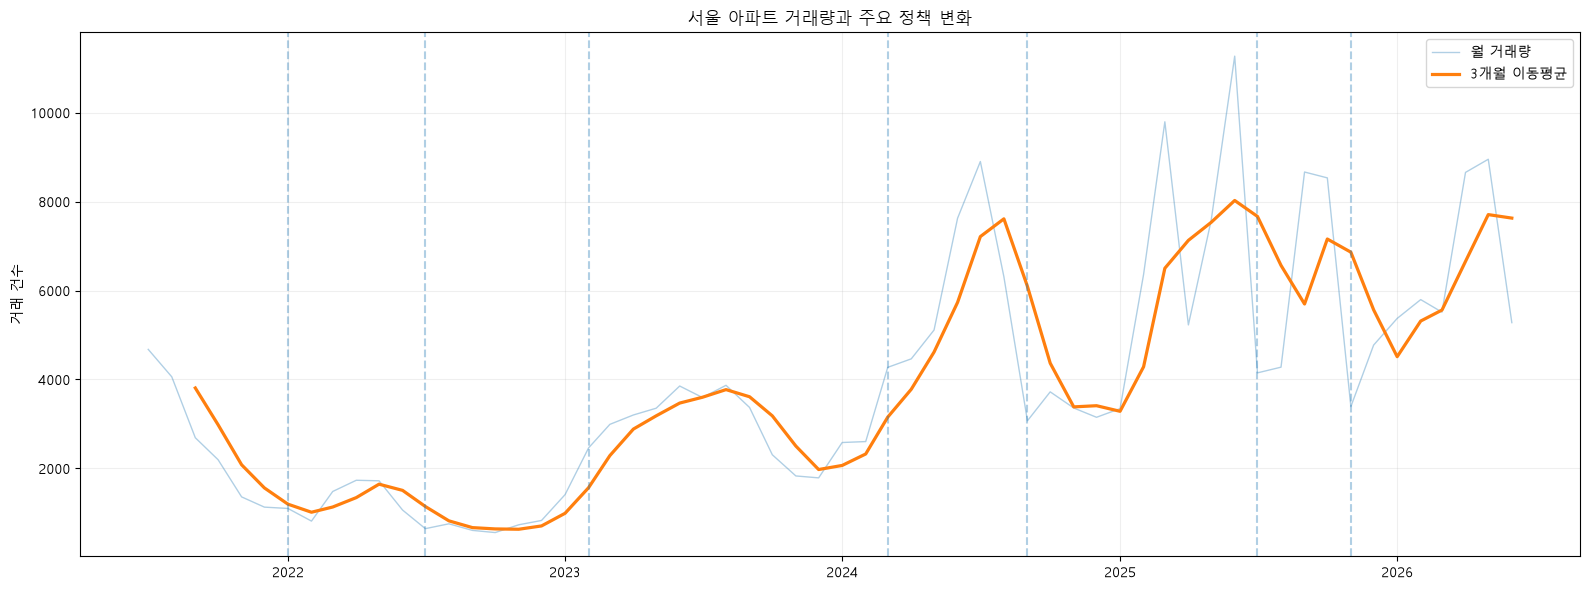

In [46]:
# ============================================================
# 거래량 + 주요 정책 이벤트
# ============================================================

policy_market["거래량_3개월평균"] = (
    policy_market["거래량"]
    .rolling(3)
    .mean()
)

fig, ax = plt.subplots(
    figsize=(16, 6)
)

ax.plot(
    policy_market["거래월일자"],
    policy_market["거래량"],
    linewidth=1,
    alpha=0.35,
    label="월 거래량",
)

ax.plot(
    policy_market["거래월일자"],
    policy_market["거래량_3개월평균"],
    linewidth=2.3,
    label="3개월 이동평균",
)

for date in key_policy_events:
    ax.axvline(
        date,
        linestyle="--",
        alpha=0.35,
    )

ax.set_title(
    "서울 아파트 거래량과 주요 정책 변화"
)
ax.set_ylabel("거래 건수")
ax.set_xlabel("")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

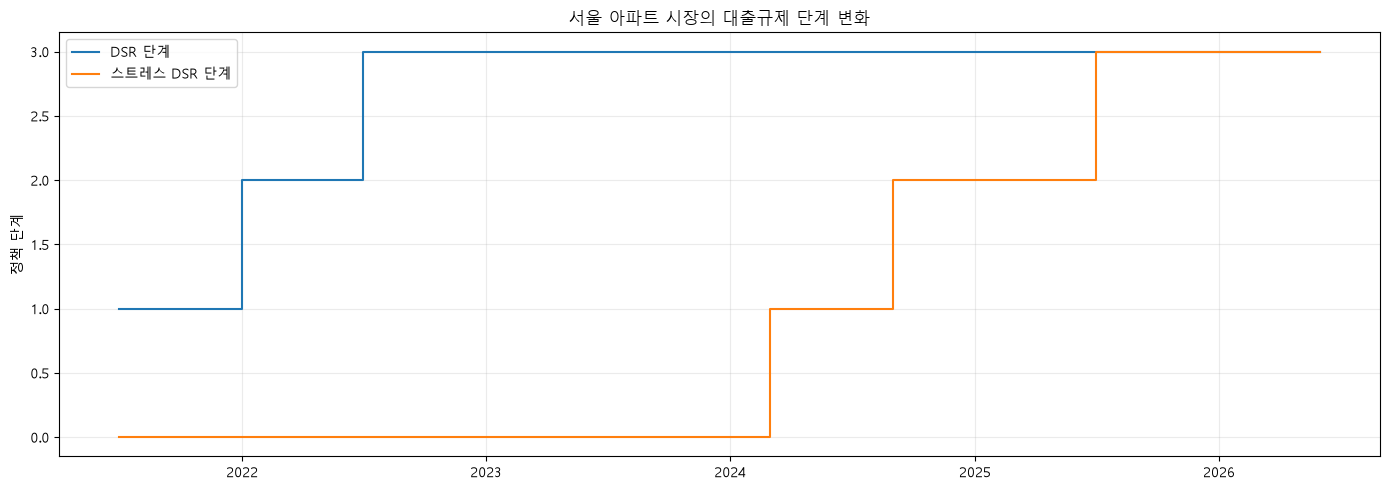

In [47]:
# ============================================================
# 정책 상태 변화
# ============================================================

monthly_policy = (
    df
    .groupby("거래월일자")
    .agg(
        DSR단계=("DSR단계", "first"),
        스트레스DSR단계=(
            "스트레스DSR단계",
            "first",
        ),
        규제지역_거래비율=(
            "규제지역여부",
            "mean",
        ),
        주담대규제강화여부=(
            "주담대규제강화여부",
            "first",
        ),
    )
    .reset_index()
)

fig, ax = plt.subplots(
    figsize=(14, 5)
)

ax.step(
    monthly_policy["거래월일자"],
    monthly_policy["DSR단계"],
    where="post",
    label="DSR 단계",
)

ax.step(
    monthly_policy["거래월일자"],
    monthly_policy["스트레스DSR단계"],
    where="post",
    label="스트레스 DSR 단계",
)

ax.set_title(
    "서울 아파트 시장의 대출규제 단계 변화"
)
ax.set_ylabel("정책 단계")
ax.set_xlabel("")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [48]:
# ============================================================
# 가격 변화율과 금리 변화
# ============================================================

macro_change = monthly_macro.copy()

macro_change["평당가_월변화율"] = (
    macro_change["매매평당가"]
    .pct_change()
    * 100
)

macro_change["주담대금리_월변화"] = (
    macro_change["주담대금리"]
    .diff()
)

print(
    macro_change[
        [
            "평당가_월변화율",
            "주담대금리_월변화",
        ]
    ]
    .corr()
)

           평당가_월변화율  주담대금리_월변화
평당가_월변화율   1.000000  -0.119815
주담대금리_월변화 -0.119815   1.000000


주요 대출·규제 정책 시행 시점과 서울 아파트 가격 및 거래량의 변화를 비교한 결과, 일부 정책 변화와 시장 전환 시점이 겹치는 구간이 확인되었다. 다만 금리, 지역별 수요, 전세시장 등 다양한 요인이 동시에 작용하므로 정책 시행과 가격 변화 간 직접적인 인과관계로 해석하지 않고 모델의 설명변수로 활용하였다.

In [49]:
# ============================================================
# 모델 제외 컬럼 후보
# ============================================================

id_cols = [
    "transaction_id",
]

target_related_cols = [
    "거래금액",
    "log_price",
    "평당가",
    "log_평당가",
]

post_transaction_cols = [
    "등기일자",
    "해제여부",
    "해제사유발생일",
    "매도자",
    "매수자",
]

raw_address_cols = [
    "도로명",
    "지번",
    "아파트동명",
]

exclude_cols = (
    id_cols
    + target_related_cols
    + post_transaction_cols
    + raw_address_cols
)

print("제외 후보 수:", len(exclude_cols))
print(exclude_cols)

제외 후보 수: 13
['transaction_id', '거래금액', 'log_price', '평당가', 'log_평당가', '등기일자', '해제여부', '해제사유발생일', '매도자', '매수자', '도로명', '지번', '아파트동명']


In [50]:
# ============================================================
# 누수 위험 컬럼 검색
# ============================================================

leak_keywords = [
    "거래금액",
    "평당가",
    "등기",
    "해제",
    "매수자",
    "매도자",
]

leak_candidates = [
    col
    for col in df.columns
    if any(
        keyword in col
        for keyword in leak_keywords
    )
]

print(
    "\n".join(
        leak_candidates
    )
)

거래금액
해제여부
해제사유발생일
등기일자
매도자
매수자
평당가
log_평당가
구_전월_중위평당가
전세평당가_전월
전세평당가_과거3개월
전세평당가_과거6개월


In [51]:
# ============================================================
# 수치형 Feature와 log_price 상관관계
# ============================================================

numeric_df = (
    df
    .select_dtypes(
        include="number"
    )
)

target_corr = (
    numeric_df
    .corr()["log_price"]
    .drop(
        labels=[
            "log_price",
        ],
        errors="ignore",
    )
    .sort_values(
        key=abs,
        ascending=False,
    )
)

display(
    target_corr
    .head(30)
    .to_frame(
        "log_price_상관"
    )
)

,log_price_상관
거래금액,0.851105
log_평당가,0.766512
평당가,0.728307
전용면적,0.661250
구_과거6개월_중위가격,0.601451
구_과거3개월_중위가격,0.596846
구_전월_중위평당가,0.588806
구_전월_중위가격,0.586800
전세평당가_과거3개월,0.563699
전세평당가_과거6개월,0.563001


In [52]:
# ============================================================
# 누수 제거 후 상관관계
# ============================================================

safe_corr = (
    target_corr
    .drop(
        labels=[
            col
            for col in exclude_cols
            if col in target_corr.index
        ],
        errors="ignore",
    )
)

display(
    safe_corr
    .head(30)
    .to_frame(
        "log_price_상관"
    )
)

,log_price_상관
전용면적,0.661250
구_과거6개월_중위가격,0.601451
구_과거3개월_중위가격,0.596846
구_전월_중위평당가,0.588806
구_전월_중위가격,0.586800
전세평당가_과거3개월,0.563699
전세평당가_과거6개월,0.563001
전세평당가_전월,0.550990
전세가율_과거6개월,-0.502434
전세가율_과거3개월,-0.485987


In [53]:
# ============================================================
# 모델 제외 컬럼 정리
# ============================================================

exclude_cols = [
    # ID
    "transaction_id",

    # Target / Target 파생
    "거래금액",
    "log_price",
    "평당가",
    "log_평당가",

    # 거래 이후 정보
    "등기일자",
    "해제여부",
    "해제사유발생일",
    "매도자",
    "매수자",

    # 원본 주소 / 식별용 문자열
    "도로명",
    "지번",
    "아파트동명",

    # 의미 없는 코드형 숫자
    "법정동시군구코드",
    "법정동읍면동코드",
    "법정동지번코드",
    "법정동본번코드",
    "법정동부번코드",
    "도로명시군구코드",
    "도로명코드",
    "도로명일련번호코드",
    "도로명지상지하코드",
    "도로명건물본번호코드",
    "도로명건물부번호코드",
    "시군구코드",
]

exclude_cols = [
    col
    for col in exclude_cols
    if col in df.columns
]

print("제외 컬럼 수:", len(exclude_cols))
print(exclude_cols)

제외 컬럼 수: 25
['transaction_id', '거래금액', 'log_price', '평당가', 'log_평당가', '등기일자', '해제여부', '해제사유발생일', '매도자', '매수자', '도로명', '지번', '아파트동명', '법정동시군구코드', '법정동읍면동코드', '법정동지번코드', '법정동본번코드', '법정동부번코드', '도로명시군구코드', '도로명코드', '도로명일련번호코드', '도로명지상지하코드', '도로명건물본번호코드', '도로명건물부번호코드', '시군구코드']


In [54]:
# ============================================================
# 범주형 Feature 확인
# ============================================================

model_candidate_cols = [
    col
    for col in df.columns
    if col not in exclude_cols
]

categorical_cols = (
    df[model_candidate_cols]
    .select_dtypes(
        include=[
            "object",
            "category",
        ]
    )
    .columns
    .tolist()
)

print("범주형 컬럼 수:", len(categorical_cols))

for col in categorical_cols:
    print(
        col,
        "→",
        df[col].nunique(dropna=False),
    )

범주형 컬럼 수: 23
단지일련번호 → 7871
거래유형 → 3
중개사소재지 → 2280
토지임대부아파트여부 → 2
층_구분 → 3
시도명 → 1
연식_구분 → 5
검색주소 → 7821
최근접유치원 → 792
최근접초등학교 → 597
최근접중학교 → 383
최근접고등학교 → 289
최근접역 → 338
최근접노선 → 23
역세권_구간 → 4
최근접응급의료기관 → 74
최근접응급의료기관분류 → 4
최근접대규모점포 → 327
최근접대규모점포업태 → 8
최근접주요일자리 → 10
전세피처출처_전월 → 3
전세피처출처_과거3개월 → 3
전세피처출처_과거6개월 → 3


In [55]:
# ============================================================
# 숫자형 모델 후보
# ============================================================

numeric_candidate_cols = (
    df[model_candidate_cols]
    .select_dtypes(
        include="number"
    )
    .columns
    .tolist()
)

print(
    "숫자형 후보:",
    len(numeric_candidate_cols),
)

숫자형 후보: 70


In [56]:
# ============================================================
# V1 Baseline 범주형 Feature
# ============================================================

baseline_cat_cols = [
    "거래유형",
    "토지임대부아파트여부",
    "최근접노선",
    "최근접응급의료기관분류",
    "최근접대규모점포업태",
    "최근접주요일자리",
    "전세피처출처_전월",
    "전세피처출처_과거3개월",
    "전세피처출처_과거6개월",
]

print("Baseline 범주형:", len(baseline_cat_cols))

for col in baseline_cat_cols:
    print(
        col,
        "→",
        df[col].nunique(dropna=False),
    )

Baseline 범주형: 9
거래유형 → 3
토지임대부아파트여부 → 2
최근접노선 → 23
최근접응급의료기관분류 → 4
최근접대규모점포업태 → 8
최근접주요일자리 → 10
전세피처출처_전월 → 3
전세피처출처_과거3개월 → 3
전세피처출처_과거6개월 → 3


In [57]:
# ============================================================
# 범주형 제외 Feature
# ============================================================

drop_cat_cols = [
    "단지일련번호",
    "중개사소재지",
    "층_구분",
    "시도명",
    "연식_구분",
    "검색주소",
    "최근접유치원",
    "최근접초등학교",
    "최근접중학교",
    "최근접고등학교",
    "최근접역",
    "역세권_구간",
    "최근접응급의료기관",
    "최근접대규모점포",
]

In [58]:
# ============================================================
# 숫자형 모델 후보 전체 확인
# ============================================================

numeric_summary = pd.DataFrame({
    "dtype": df[numeric_candidate_cols].dtypes.astype(str),
    "고유값수": [
        df[col].nunique(dropna=False)
        for col in numeric_candidate_cols
    ],
    "결측수": [
        df[col].isna().sum()
        for col in numeric_candidate_cols
    ],
})

display(numeric_summary)

,dtype,고유값수,결측수
전용면적,float64,11090,0
계약년도,int64,6,0
계약월,int64,12,0
계약일,int64,31,0
층,int64,71,0
...,...,...,...
DSR단계,int64,3,0
스트레스DSR단계,int64,4,0
규제지역여부,int64,2,0
주담대규제강화여부,int64,2,0


In [59]:
# ============================================================
# 숫자형 후보 컬럼 목록
# ============================================================

for i, col in enumerate(
    numeric_candidate_cols,
    start=1,
):
    print(f"{i:02d}. {col}")

01. 전용면적
02. 계약년도
03. 계약월
04. 계약일
05. 층
06. 건축년도
07. 거래연월
08. 거래년도
09. 거래월
10. 분기
11. 경과월
12. 월_sin
13. 월_cos
14. 연식
15. 구_전월_중위가격
16. 구_전월_중위평당가
17. 구_전월_거래량
18. 구_과거3개월_중위가격
19. 구_과거6개월_중위가격
20. 구_과거3개월_거래량
21. 구_과거6개월_거래량
22. 구_전월_가격변화율
23. 서울_전월_중위가격
24. 서울_과거3개월_중위가격
25. 서울_과거6개월_중위가격
26. 서울_전월_거래량
27. 서울_과거3개월_거래량
28. 서울_전월_가격변화율
29. 위도
30. 경도
31. 유치원거리_m
32. 초등학교거리_m
33. 중학교거리_m
34. 고등학교거리_m
35. 역세권거리_m
36. 응급의료기관거리_m
37. 응급의료기관거리_km
38. 대규모점포거리_m
39. 대규모점포거리_km
40. 주요일자리거리_m
41. 주요일자리거리_km
42. 전세평당가_전월
43. 전세평당가_과거3개월
44. 전세평당가_과거6개월
45. 전세거래량_전월
46. 전세거래량_과거3개월
47. 전세거래량_과거6개월
48. 전세가율_전월
49. 전세가율_과거3개월
50. 전세가율_과거6개월
51. 월세거래량_전월
52. 월세거래량_과거3개월
53. 월세거래량_과거6개월
54. 월세비중_전월
55. 월세비중_과거3개월
56. 월세비중_과거6개월
57. 기준금리_전월
58. 기준금리_3개월변화
59. 기준금리_6개월변화
60. 주담대금리_전월
61. 주담대금리_3개월변화
62. 주담대금리_6개월변화
63. 전세대출금리_전월
64. 전세대출금리_3개월변화
65. 전세대출금리_6개월변화
66. DSR단계
67. 스트레스DSR단계
68. 규제지역여부
69. 주담대규제강화여부
70. 고가주택_주담대한도차등여부


In [60]:
# ============================================================
# 숫자형 Feature 고상관 중복 확인
# ============================================================

numeric_corr = (
    df[numeric_candidate_cols]
    .corr()
    .abs()
)

upper = numeric_corr.where(
    np.triu(
        np.ones(numeric_corr.shape),
        k=1,
    ).astype(bool)
)

high_corr_pairs = []

for col in upper.columns:

    related = upper.index[
        upper[col] >= 0.995
    ]

    for row in related:
        high_corr_pairs.append(
            [
                row,
                col,
                upper.loc[row, col],
            ]
        )

high_corr_df = pd.DataFrame(
    high_corr_pairs,
    columns=[
        "Feature_1",
        "Feature_2",
        "상관계수",
    ],
)

display(high_corr_df)

,Feature_1,Feature_2,상관계수
0,계약년도,거래연월,0.999776
1,계약년도,거래년도,1.000000
2,거래연월,거래년도,0.999776
3,계약월,거래월,1.000000
4,응급의료기관거리_m,응급의료기관거리_km,1.000000
5,대규모점포거리_m,대규모점포거리_km,1.000000
6,주요일자리거리_m,주요일자리거리_km,1.000000


In [61]:
for i in range(25, 66):
    print(
        f"{i + 1:02d}.",
        numeric_candidate_cols[i],
    )

26. 서울_전월_거래량
27. 서울_과거3개월_거래량
28. 서울_전월_가격변화율
29. 위도
30. 경도
31. 유치원거리_m
32. 초등학교거리_m
33. 중학교거리_m
34. 고등학교거리_m
35. 역세권거리_m
36. 응급의료기관거리_m
37. 응급의료기관거리_km
38. 대규모점포거리_m
39. 대규모점포거리_km
40. 주요일자리거리_m
41. 주요일자리거리_km
42. 전세평당가_전월
43. 전세평당가_과거3개월
44. 전세평당가_과거6개월
45. 전세거래량_전월
46. 전세거래량_과거3개월
47. 전세거래량_과거6개월
48. 전세가율_전월
49. 전세가율_과거3개월
50. 전세가율_과거6개월
51. 월세거래량_전월
52. 월세거래량_과거3개월
53. 월세거래량_과거6개월
54. 월세비중_전월
55. 월세비중_과거3개월
56. 월세비중_과거6개월
57. 기준금리_전월
58. 기준금리_3개월변화
59. 기준금리_6개월변화
60. 주담대금리_전월
61. 주담대금리_3개월변화
62. 주담대금리_6개월변화
63. 전세대출금리_전월
64. 전세대출금리_3개월변화
65. 전세대출금리_6개월변화
66. DSR단계


In [62]:
# ============================================================
# V1 Baseline 숫자형 Feature 확정
# 거리 단위는 모두 m로 통일
# ============================================================

drop_numeric_cols = [
    # 중복 시간 변수
    "계약년도",
    "계약월",
    "계약일",
    "건축년도",
    "거래연월",
    "거래년도",
    "거래월",
    "분기",

    # 거리 단위 중복: m만 사용
    "응급의료기관거리_km",
    "대규모점포거리_km",
    "주요일자리거리_km",
]

baseline_numeric_cols = [
    col
    for col in numeric_candidate_cols
    if col not in drop_numeric_cols
]

print(
    "Baseline 숫자형:",
    len(baseline_numeric_cols),
)

Baseline 숫자형: 59


In [63]:
location_distance_cols = [
    "역세권거리_m",
    "유치원거리_m",
    "초등학교거리_m",
    "중학교거리_m",
    "고등학교거리_m",
    "응급의료기관거리_m",
    "대규모점포거리_m",
    "주요일자리거리_m",
]

In [64]:
# ============================================================
# V1 Baseline 최종 Feature
# ============================================================

baseline_feature_cols = (
    baseline_numeric_cols
    + baseline_cat_cols
)

TARGET = "log_price"

print(
    "숫자형:",
    len(baseline_numeric_cols),
)

print(
    "범주형:",
    len(baseline_cat_cols),
)

print(
    "전체 Feature:",
    len(baseline_feature_cols),
)

print(
    "Target:",
    TARGET,
)

숫자형: 59
범주형: 9
전체 Feature: 68
Target: log_price


In [65]:
# ============================================================
# 최종 Feature 검증
# ============================================================

forbidden_cols = [
    "transaction_id",
    "거래금액",
    "평당가",
    "log_평당가",
    "등기일자",
    "해제여부",
    "해제사유발생일",
    "매도자",
    "매수자",
]

leak_found = [
    col
    for col in forbidden_cols
    if col in baseline_feature_cols
]

duplicate_features = (
    pd.Index(
        baseline_feature_cols
    )
    .duplicated()
    .sum()
)

missing_features = [
    col
    for col in baseline_feature_cols
    if col not in df.columns
]

print(
    "누수 위험 컬럼:",
    leak_found,
)

print(
    "Feature 중복:",
    duplicate_features,
)

print(
    "존재하지 않는 Feature:",
    missing_features,
)

누수 위험 컬럼: []
Feature 중복: 0
존재하지 않는 Feature: []
